# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Los Unitarios

# Integrantes
1. Mariano Papaleo, LU: 848/21

2. Lucila Echegaray, LU: 561/23

3. Gastón Guzman, LU: 61/22

4. Ezequiel Flores, LU: 918/23

In [1]:
import alc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

1. a) Sabemos que $Rango(Q) = dim(Im(Q))$
Por Teorema de la Dimensión:  \
$dim(Nu(Q))  + dim(Im(Q)) = n$, donde $n = Col(Q)$ \
$dim(Nu(Q))  + Rango(Q) = 12$ \
$Rango(Q) = 12 - dim(Nu(Q))$ \
Por ejemplo, si $ m = (2, 4) ⟹ 2 (1, 2)$ entonces $2$ es el factor de escala.
No puede ocurrir que el $Nu(Q) = \left\{ (1, 0) , (0, 1)\right\}$ porque entonces hay más de un factor de escala ya que podemos representar el $Nu(Q)$ como $a(1, 0) + b(0,1)$ siendo $a$ y $b$ los factores de escala.
Ademas, $m \neq 0$ porque necesitamos una solución no nula.
Por lo tanto, $dim(Nu(Q)) = 1$, siendo la cuenta final: \
$Rango(Q) = 12 - dim(Nu(Q)) = 12 - 1 = 11$ \
Por otra parte, sabemos que $Rango(Q) \leq min(Filas(Q),\ Columnas(Q))$ con $Filas(Q) = 2n$, $Columnas(Q) = 12$ \
$Rango(Q) \leq min(2n, 12)$ \
$11 \leq min(2n, 12)$ \
$11 \leq 2n$ \
$5,5 \leq n ⟹ n   ≥  6$  
Como minimo van a ser necesarios 6 puntos para asegurar la solución. \
Finalmente, los puntos $P_i = (U_i, V_i, W_i, 1)$ no deben ser coplanares, ya que si lo fueran pertenecerían a un mismo plano,
por tanto existiría un vector $V = (a, b, c, d)$ no nulo tal que $P_i  V$ daría $0$ para todo $i$. \
Lo fuerte de esto es que un solo vector $V$ anula los puntos $P_i\ \forall i$.
Por lo tanto, existen 3 formas de escribir el vector $m \in \mathbb{R}^{12}$  de manera que $Qm = 0$.
Tenemos que los vectores (de 12 coordenadas) $z_1 = (v, \mathbf{0}, \mathbf{0})$, $z_2 = (\mathbf{0}, v, \mathbf{0})$y $z_3 = (\mathbf{0}, \mathbf{0}, v)$
(donde $\mathbf{0} = (0, 0, 0, 0)$) pertenecerían al núcleo de $Q$, ya que $Qz_1 = 0$, $Qz_2 = 0$ y $Qz_3 = 0$.
Lo que implicaría que $dim(Nu(Q)) \geq 3$ y entonces el rango de $Q$ sería 9, que es menor a 11. Entonces, hay infinitas soluciones no nulas.

1) b) Queremos minimizar $||Qm||^2$ y como $Q=UΣV^T$ reescribimos $||Qm||^2=||UΣV^Tm||^2$ como $U$ es ortogonal, no modifica a la norma $ ⟹ ||UΣV^Tm||^2=||Σ(V^Tm)||^2$ \
  Llamamos $y=V^Tm ∈ R^{12}$ y como $V$ tambien es ortogonal, $||y||=||V^Tm||=||m||=1$, entonces queda minimizar: $||Σy||^2=Σ_{i=1}^{12} σ_i^2 y_i^2$ \
Como $σ_{12}$ es el menor valor singular queda acotado: \
$Σ_{i=1}^{12} σ_i^2y_i^2 \geq σ_{12}^2 Σ_{i=1}^{12}y_i^2=σ_{12}^2||y||^2=σ_{12}^2$ \
Este minimo se alcanza si tomamos $y=e_{12}=(0,0,...,1)$ y como $y=V^Tm⟹ Vy=m ⟹ Ve_{12}=v_{12}=m$ \
Luego, $m$ es el autovector asociado al menor autovalor de la matriz simétrica $Q^TQ$

---


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

In [2]:
# Cargamos las coordenadas 2D de las esquinas detectadas y las 3D de referencia
todosLosPuntos2D = np.loadtxt('calib/3d/detected_corners.txt')
puntos3D = np.loadtxt('calib/3d/p_W_corners.txt', delimiter=',')

# Tomamos la primera fila (primera imagen) y la redimensionamos a 12 filas x 2 columnas (u, v)
puntos2D = todosLosPuntos2D[0].reshape(12, 2)

Q = alc.obtenerQ3d(puntos2D, puntos3D)
M = alc.resolverDLT3D(Q)
R, t, K = alc.devolverMatricesCalibracion3d(M, restriccion=False)

print("Matriz intrínseca K:")
print(K)
print("\nMatriz de rotación R:")
print(R)
print("\nVector de traslación t:")
print(t)

# Verificamos el error medio de reproyección sobre los 12 puntos
proy = []
for i in range(12):
    Pc = alc.prodMat(R, puntos3D[i]).flatten() + t
    p_img = alc.prodMat(K, Pc).flatten()
    proy.append([p_img[0] / p_img[2], p_img[1] / p_img[2]])
proy = np.array(proy)
err_medio = np.mean(np.sqrt((proy[:, 0] - puntos2D[:, 0])**2 + (proy[:, 1] - puntos2D[:, 1])**2))
print(f"\nError medio de reproyección: {err_medio:.3f} px")

Matriz intrínseca K:
[[ 4.25859862e+02 -1.56351847e-02  3.54418499e+02]
 [ 0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

Matriz de rotación R:
[[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]

Vector de traslación t:
[-18.16793831 -14.50326886  40.59128918]

Error medio de reproyección: 0.331 px


Calcular un nuevo set de parámetros imponiendo:

- b) $\alpha_u = \alpha_v$
- c) $K_{12}=0$
- d) Ambas restricciones simultáneamente ($\alpha_u = \alpha_v$ y $K_{12}=0$)

In [3]:
# Restricción b: escala isotrópica (alpha_u = alpha_v)
R_esc, t_esc, K_esc = alc.devolverMatricesCalibracion3d(M, restriccion_escala=True)

# Restricción c: sesgo nulo (gamma = K12 = 0)
R_sesg, t_sesg, K_sesg = alc.devolverMatricesCalibracion3d(M, gamma_cero=True)

# Restricción d: ambas restricciones simultáneamente
R_rest, t_rest, K_rest = alc.devolverMatricesCalibracion3d(M, restriccion=True)

print("Matriz K con alpha_u = alpha_v:")
print(K_esc)
print("\nMatriz K con K12 = 0:")
print(K_sesg)
print("\nMatriz K con ambas restricciones (alpha_u = alpha_v y K12 = 0):")
print(K_rest)

Matriz K con alpha_u = alpha_v:
[[ 4.25212585e+02 -1.56351847e-02  3.54418499e+02]
 [ 0.00000000e+00  4.25212585e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

Matriz K con K12 = 0:
[[425.8598625    0.         354.4184987 ]
 [  0.         424.56530696 256.85335528]
 [  0.           0.           1.        ]]

Matriz K con ambas restricciones (alpha_u = alpha_v y K12 = 0):
[[425.21258473   0.         354.4184987 ]
 [  0.         425.21258473 256.85335528]
 [  0.           0.           1.        ]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

**¿Qué rango debe tener $Q \in \mathbb{R}^{2n \times 9}$ para asegurar una solución única de $H$ a menos de un factor de escala?**

Por el Teorema de la Dimensión:
$$\text{rg}(Q) + \dim(\text{Nu}(Q)) = 9$$

Para que el sistema homogéneo $Q h = 0$ admita una solución no nula única salvo por un factor de escala, el espacio nulo de $Q$ debe tener dimensión 1 ($\dim(\text{Nu}(Q)) = 1$). Por lo tanto:
$$\text{rg}(Q) = 9 - 1 = 8$$

La matriz $Q$ debe tener rango 8. Como cada correspondencia entre un punto del plano y su imagen aporta 2 ecuaciones linealmente independientes, se necesitan al menos $n \ge 4$ puntos coplanares no colineales para determinar unívocamente la homografía $H$ (a menos de escala).

a) Obtener la matriz $\mathbf{K}$ mediante el método de Zhang.

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_5.png}$ y $\texttt{Im\_R\_10.png}$, y verificar la reproyección.

In [4]:
# Cargamos las esquinas detectadas en las imágenes del tablero
corners = np.loadtxt('calib/coplanar/detected_corners_coplanar.txt')
num_vistas = len(corners)

# Generamos las coordenadas métricas del tablero (11x7 esquinas internas, espaciadas 30 mm)
objPts = np.zeros((77, 2))
for j in range(7):
    for i in range(11):
        objPts[j * 11 + i] = [i * 30.0, j * 30.0]

# Estimamos la homografía Hj para cada vista
H_list = []
for k in range(num_vistas):
    imgPts_k = corners[k].reshape(77, 2)
    H_k = alc.resolverHomografia(objPts, imgPts_k)
    H_list.append(H_k)

# Armamos la matriz A de Zhang y calculamos la matriz intrínseca K
A = alc.armarA(H_list)
K_zhang = alc.calcularMatrizK2D(A)

print("Matriz intrínseca K (Método de Zhang):")
print(K_zhang)
print(f"\nalpha_u: {K_zhang[0, 0]:.2f}, alpha_v: {K_zhang[1, 1]:.2f}")
print(f"Punto principal: ({K_zhang[0, 2]:.2f}, {K_zhang[1, 2]:.2f})")
print(f"Sesgo gamma: {K_zhang[0, 1]:.4f}")

# Calculamos la pose de las vistas 1, 5 y 10
for idx in [0, 4, num_vistas - 1]:
    R_v, t_v = alc.obtenerPose2D(H_list[idx], K_zhang)
    print(f"\nPose Vista {idx + 1}:")
    print("  t (mm):", t_v)
    print("  R:\n", R_v)

# Reproyección sobre la primera vista (Im_R_1.png)
img_1 = plt.imread('calib/coplanar/Im_R_1.png')
imgPts_1 = corners[0].reshape(77, 2)
R_1, t_1 = alc.obtenerPose2D(H_list[0], K_zhang)

proy_1 = []
for pt in objPts:
    Pc = alc.prodMat(R_1, np.array([pt[0], pt[1], 0.0])).flatten() + t_1
    p = alc.prodMat(K_zhang, Pc).flatten()
    proy_1.append([p[0] / p[2], p[1] / p[2]])
proy_1 = np.array(proy_1)

error_medio_1 = np.mean(np.sqrt((proy_1[:, 0] - imgPts_1[:, 0])**2 + (proy_1[:, 1] - imgPts_1[:, 1])**2))
print(f"\nError medio de reproyección en Vista 1: {error_medio_1:.3f} px")

plt.figure(figsize=(8, 6))
plt.imshow(img_1)
plt.scatter(imgPts_1[:, 0], imgPts_1[:, 1], color='cyan', s=25, label='Detectados')
plt.scatter(proy_1[:, 0], proy_1[:, 1], color='red', marker='+', s=35, label='Reproyectados')
plt.title(f'Ejercicio 3: Reproyección en Im_R_1.png (Error: {error_medio_1:.2f} px)')
plt.legend()
plt.tight_layout()
plt.show()

Matriz intrínseca K (Método de Zhang):
[[ 7.46375028e+02 -6.71992367e-01  5.20596834e+02]
 [ 0.00000000e+00  7.57670944e+02  2.98737943e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

alpha_u: 746.38, alpha_v: 757.67
Punto principal: (520.60, 298.74)
Sesgo gamma: -0.6720

Pose Vista 1:
  t (mm): [-109.37623068 -141.47097847  551.20434702]
  R:
 [[ 0.99954424 -0.01188654 -0.02774924]
 [ 0.01210733  0.99989626  0.0078021 ]
 [ 0.02765362 -0.00813451  0.99958447]]

Pose Vista 5:
  t (mm): [ -75.10058349 -158.55256528  536.54287248]
  R:
 [[ 0.99495763 -0.06649987 -0.07508044]
 [ 0.06773077  0.99760588  0.01396611]
 [ 0.07397194 -0.01898094  0.99707967]]

Pose Vista 10:
  t (mm): [ -96.58686536 -154.10180633  541.86443915]
  R:
 [[ 0.99736898  0.06801482 -0.02508178]
 [-0.06323154  0.98543672  0.15784878]
 [ 0.03545256 -0.15584752  0.9871447 ]]

Error medio de reproyección en Vista 1: 0.239 px


<Figure size 800x600 with 1 Axes>

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

La foto que nos piden evaluar es $\texttt{gol-enzo.png}$. 

Asi que empezamos por cargar la imagen y visualizarla:

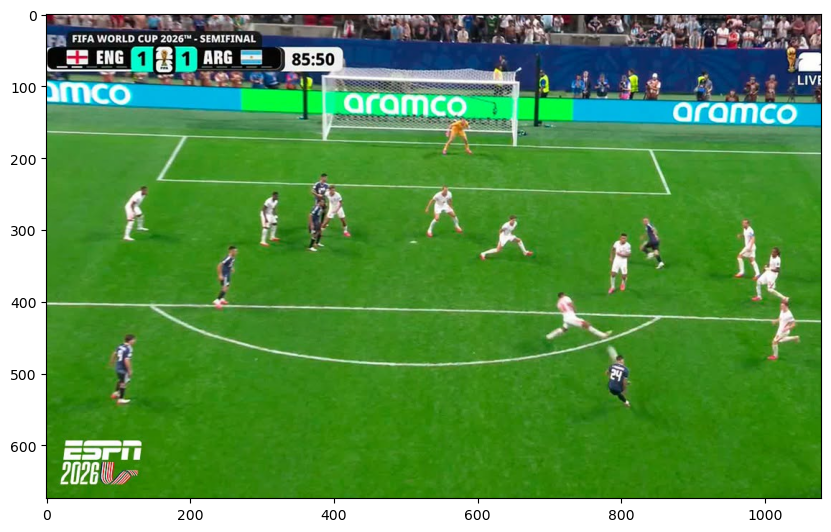

In [5]:
# Cargamos la imagen
imagenEnzo = mpimg.imread("futbol/test-gol-enzo.png")
plt.figure(figsize=(10, 10))
plt.imshow(imagenEnzo)

Para calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco necesitamos obtener las coordenadas de la cancha y de la imagen.

En la foto $\texttt{estadio-azteca.png}$. tenemos la medidas reales de la cancha, mientras que de la imagen anterior sacamos las coordenadas en pixeles.

Dimensiones de la imagen: (674, 1079, 4)


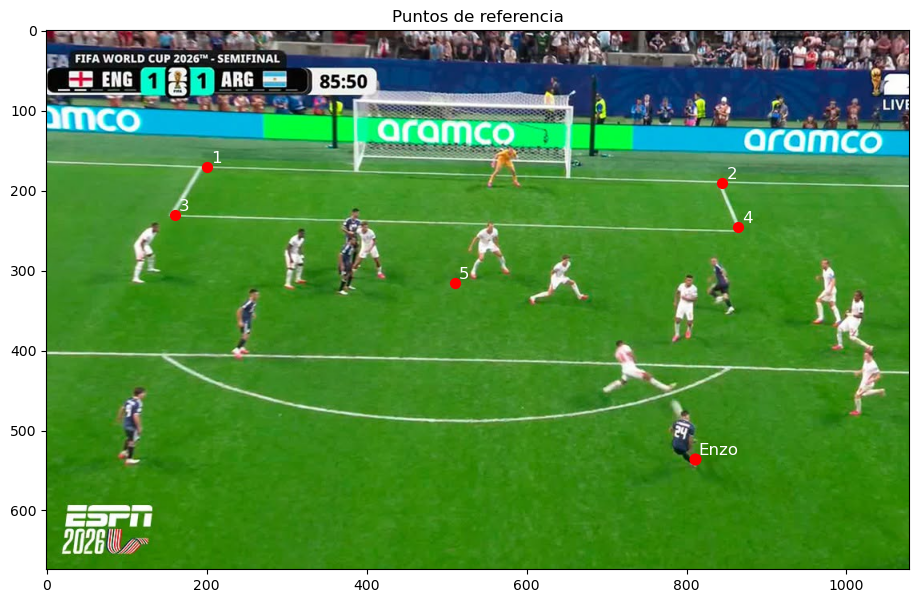

In [6]:
# Coordenadas reales (U, V) de la cancha
U_cancha = 105  # Largo total de la cancha
V_cancha = 68   # Ancho total de la cancha
U_grande = 16.5 # Largo del Area Grande
V_grande = 40.32 #Ancho del Area Grande
U_chica = 5.5   # Largo del area chica
V_chica = 18.32 # Ancho del area chica
U_penal = 11    

V1 = (V_cancha - V_chica) / 2  # = 24.84
punto1Cancha = np.array([0, V1])  # (0, 24.84): esquina izquierda sobre la linea de fondo 

V2 = V1 + V_chica  # = 43.16
punto2Cancha = np.array([0, V2])  # (0, 43.16): esquina derecha sobre la linea de fondo 

U3 = U_chica  # = 5.5
punto3Cancha = np.array([U3, V1])  # (5.5, 24.84): esquina izquierda del borde frontal del area chica

# Cuarta 
punto4Cancha = np.array([U3, V2])  # (5.5, 43.16): esquina derecha del borde frontal del area chica

V_penal = V_cancha / 2
punto5Cancha = np.array([U_penal, V_penal])  # (11, 34): punto penal


objPts = np.array([
    punto1Cancha,
    punto2Cancha,
    punto3Cancha,
    punto4Cancha,
    punto5Cancha
], dtype=float)

# Coordenadas (u, v) de la imagen

print("Dimensiones de la imagen:", imagenEnzo.shape)

punto1Img = np.array([200, 170])  # Esquina izquierda sobre la línea de fondo
punto2Img = np.array([845, 190])  # Esquina derecha sobre la línea de fondo
punto3Img = np.array([160, 230])  # Esquina izquierda del borde frontal
punto4Img = np.array([865, 245])  # Esquina derecha del borde frontal
punto5Img = np.array([510,315]) # Punto penal

imgPts = np.array([
    punto1Img,
    punto2Img,
    punto3Img,
    punto4Img,
    punto5Img
], dtype=float)

# Coordenadas de los pies de enzo
piesEnzoImg = np.array([810, 535])

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenEnzo)

for i, punto in enumerate(imgPts):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] + 5, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
plt.scatter(piesEnzoImg[0], piesEnzoImg[1], color="red", s=60)
plt.text(piesEnzoImg[0] + 5, piesEnzoImg[1] - 5, "Enzo",
             color="white", fontsize=12)
plt.title("Puntos de referencia")
plt.show()

Ahora bien, nuestro primer objetivo fue llevar los pies del jugador a la cancha, es decir, queremos pasar de coordenadas de la imagen $(u,v)$ a coordenadas de la cancha $(U,V)$.

Para lograr esto necesitamos $H^{-1}$, por lo tanto, creamos la funcion `calcularHomografia2D(imgPts, objPts)` para obtener la homografia $H$. Dentro de la funcion, utilizamos `obtenerQ2d` creada anteriormente para obtener la matriz $Q$, despues resolvimos $Qh = 0$ mediante SVD, donde nos quedamos con la ultima columna de $V$ ya que este es el vector asociado al menor valor singular. 

Este vector es la solucion porque buscamos un vector h que, al multiplicarlo por Q, produzca un resultado lo más cercano posible al vector nulo:

$$
\min_{\substack{\|h\|=1}} \|Qh\|^2
$$

In [7]:
# Calculamos la Homografia
H = alc.calcularHomografia2D(imgPts, objPts)
print("Homografía H:")
print(H)


Homografía H:
[[-1.08056263e+01  4.01011059e+01 -7.81285507e+02]
 [ 7.91489095e+00  1.60831073e+00  1.42134001e+02]
 [-1.72672736e-02  2.87027424e-03  1.00000000e+00]]


Ahora que tenemos la matriz $H$, tambien tenemos $H^{-1}$ que es simplemente aplicar la inversa a la homografia. Creamos la funcion `proyectarAPuntoReal(H, imgPts)` que hace el paso de coordenadas de la imagen a coordenadas del mundo real: 

$$
H^{-1}
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
=
\begin{bmatrix}
U\\
V\\
1
\end{bmatrix}
$$


In [8]:
# Transformamos los pies a coordenadas de la cancha para verificar la posicion de Enzo
U_enzo, V_enzo = alc.proyectarAPuntoReal(H, piesEnzoImg)

print("Posición de Enzo en la cancha:")
print(f"U = {U_enzo:.2f} metros")
print(f"V = {V_enzo:.2f} metros")

Posición de Enzo en la cancha:
U = 22.73 metros
V = 40.21 metros



Queda ver su distancia a la linea del arco.

Teniendo en cuenta las medidas de la imagen `estadio_azteca.png`, un arco se ubica sobre $U = 105 m$ con $V = 7,32 m$ centrado en la linea de meta. La funcion `distanciaPiesArco(H, imgPts)` calcula donde se ubica cada palo teniendo en cuenta estos datos y mediante la distancia euclidea obtiene la distancia, sobre el piso, desde los pies del jugador hasta el arco:

$$
\sqrt{(U-U_{\text{cancha}})^2+(V-V_{\text{cercano}})^2}
$$

siendo $U$ y $V$ los pies de enzo, $Ucancha$ la ubicacion $U$ del arco y $Vcercano$ el punto del arco mas cercano al jugador.

In [9]:
distancia = alc.distanciaPiesArco(H, piesEnzoImg)

print(f"Distancia de los pies de Enzo al arco: {distancia:.2f} metros")

Distancia de los pies de Enzo al arco: 22.88 metros


Pasando al punto $b)$, como queremos dibujar un circulo sobre el piso en cada jugador argentino, debemos ubicar primero a esos jugadores en la imagen.

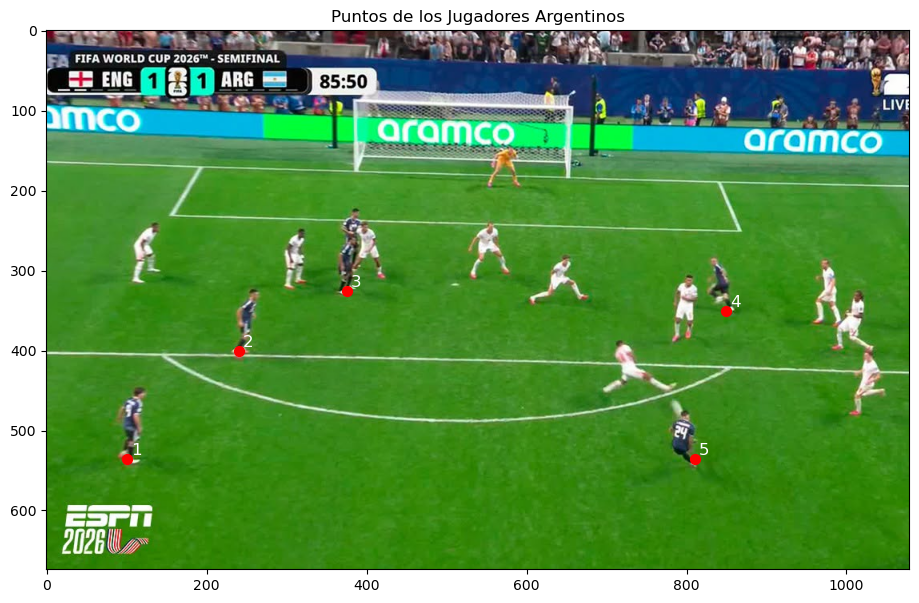

In [10]:
# Coordenadas (u, v) de cada jugador argentino en la imagen
puntoJug1Img = np.array([100, 535])  
puntoJug2Img = np.array([240, 400])  
puntoJug3Img = np.array([375, 325])  
puntoJug4Img = np.array([850, 350])  
puntoJug5Img = np.array([810, 535]) # Coordenadas de los pies de enzo

imgPtsJug = np.array([
    puntoJug1Img,
    puntoJug2Img,
    puntoJug3Img,
    puntoJug4Img,
    puntoJug5Img
], dtype=float)

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenEnzo)

for i, punto in enumerate(imgPtsJug):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] + 5, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
    
plt.title("Puntos de los Jugadores Argentinos")
plt.show()

Para resolver el ejercicio pasamos a crear la funcion `dibujarCirculosJugadores(H, jugPts)`.

Dentro de ella, empezamos proyectando cada coordenada de los jugadores de la imagen $(u, v)$ a coordenadas de la cancha $(U, V)$, mediante la funcion `proyectarAPuntoReal(H, imgPts)` creada anteriormente.

Una vez que tenemos la posicion de un jugador (Ui,Vi) definimos un circulo con los calculos:

$$
\begin{aligned}
U &= U_i + \cos(\theta)\\[6pt]
V &= V_i + \sin(\theta)
\end{aligned}
$$

porque $(U-Ui)^2 + (V-Vi)^2 = 1$, es decir, la parametrizacion corresponde a un círculo de radio 1 metro.

Luego proyectamos los puntos de esos circulos a la imagen mediante la funcion `proyectarAPuntoImagen(H, objPt)`, que realizamos en base a la ecuacion: 

$$
\lambda
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
=
H
\begin{bmatrix}
U\\
V\\
1
\end{bmatrix}
$$

Por ultimo, dibujamos los circulos proyectados sobre la imagen


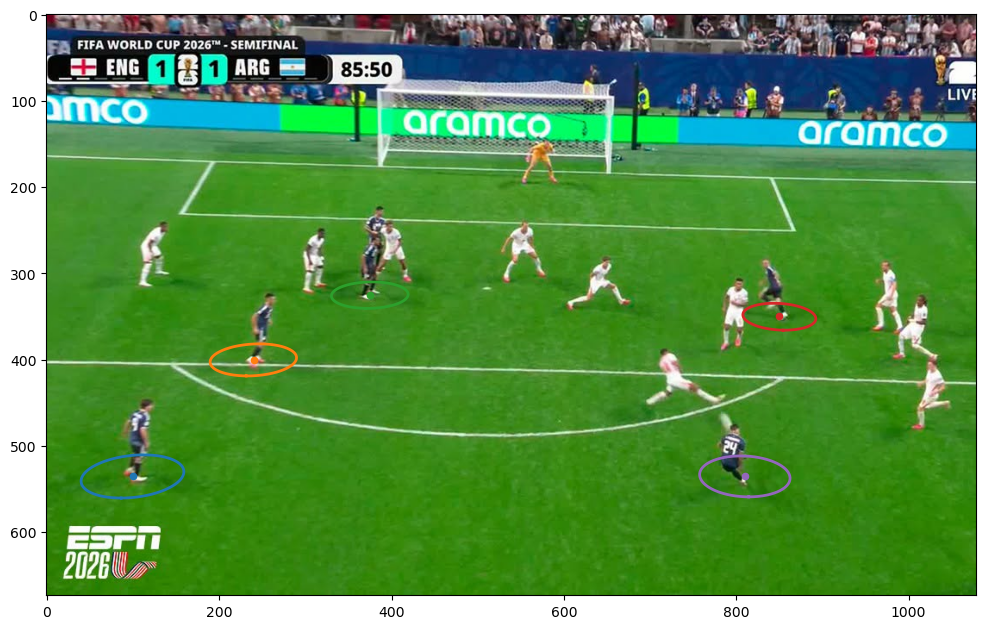

La posicion del jugador 0 es: (22.79,27.33)
La posicion del jugador 1 es: (16.51,28.70)
La posicion del jugador 2 es: (11.97,30.96)
La posicion del jugador 3 es: (13.08,41.97)
La posicion del jugador 4 es: (22.73,40.21)


In [11]:
# Cargamos la imagen de Enzo
imagenEnzo = mpimg.imread("futbol/test-gol-enzo.png")

plt.figure(figsize=(12, 8))
plt.imshow(imagenEnzo)

# Dibujamos los circulos de cada jugador argentino
posiciones = alc.dibujarCirculosJugadores(H, imgPtsJug)
for i, pos in enumerate(posiciones):
    print(f"La posicion del jugador {i} es: ({pos[0]:.2f},{pos[1]:.2f})")

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

La idea para resolver el ejercicio es definir la recta en coordenadas de la cancha y luego proyectarlo a la imagen.

Empezamos evaluando la imagen $\texttt{test-fuera-de-juego.png}$

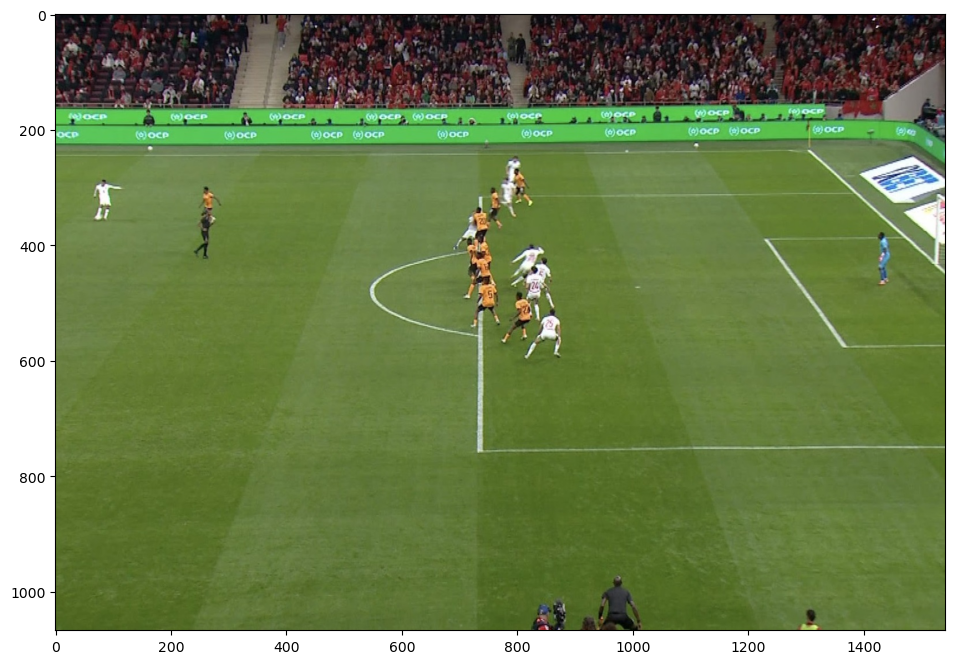

In [12]:
# Cargamos la imagen
imagenFuera = mpimg.imread("futbol/test-fuera-de-juego.png")

# La mostramos
plt.figure(figsize=(12, 8))
plt.imshow(imagenFuera)


El primer objetivo es poder identificar el pie del ultimo defensor en coordenadas reales $(Ud, Vd)$, para ello, necesitamos identificar los puntos de referencia de la cancha y la imagen para asi, generar la Homografia $H$

Dimensiones de la imagen: (1067, 1541, 3)


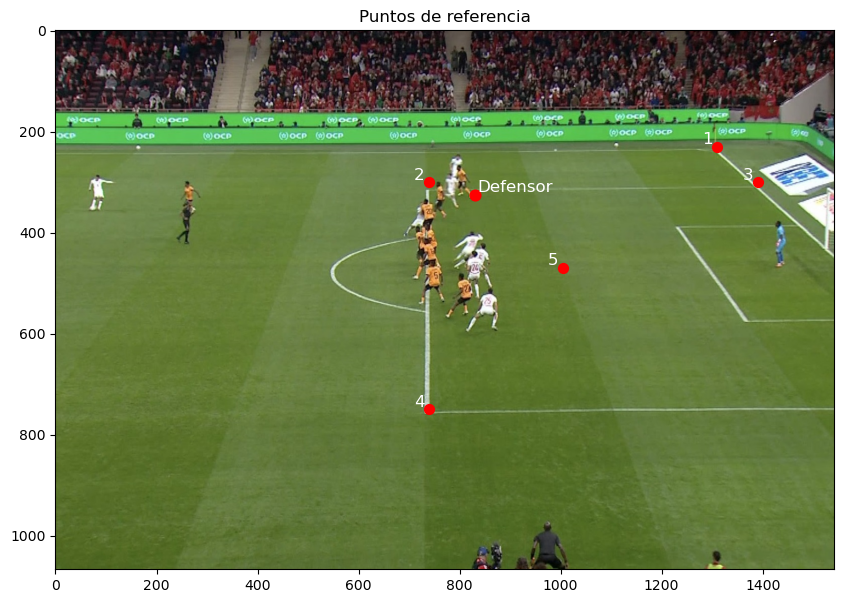

In [13]:
# Coordenadas reales (U, V) de la cancha
U_cancha = 105  # Largo total de la cancha
V_cancha = 68   # Ancho total de la cancha
U_grande = 16.5 # Largo del Area Grande
V_grande = 40.32 #Ancho del Area Grande
U_chica = 5.5   # Largo del area chica
V_chica = 18.32 # Ancho del area chica
U_penal = 11    

# Puntos de la cancha del arco derecho

punto1Cancha = np.array([U_cancha, V_cancha])  # (105, 68): Esquina superior derecha sobre la linea del fondo

U2 = U_cancha - U_grande # 88.5
V2 = (V_cancha + V_grande) / 2 # = 54.16
punto2Cancha = np.array([U2, V2])  # (88.5, 54.16): Esquina superior izquierda del area grande

punto3Cancha = np.array([U_cancha, V2])  # (105, 54.16 ): Esquina superior derecha del area grande

V4 = (V_cancha - V_grande) / 2 # = 13.84
punto4Cancha = np.array([U2, V4])  # (88.5, 13.84): Esquina inferior izquierda del area grande

U5 = U_cancha - U_penal # = 94
V_penal = V_cancha / 2  # = 34
punto5Cancha = np.array([U5 ,V_penal ])  # (94, 34): Punto penal

objPts = np.array([
    punto1Cancha,
    punto2Cancha,
    punto3Cancha,
    punto4Cancha,
    punto5Cancha
], dtype=float)

# Coordenadas (u, v) de la imagen

print("Dimensiones de la imagen:", imagenFuera.shape)

punto1Img = np.array([1310,230 ])  # Esquina superior derecha sobre la linea del fondo
punto2Img = np.array([740,300 ])  # Esquina superior izquierda del area grande
punto3Img = np.array([1390,300])  # Esquina superior derecha del area grande
punto4Img = np.array([740,750 ])  # Esquina inferior izquierda del area grande
punto5Img = np.array([1005,470]) # Punto penal

imgPts = np.array([
    punto1Img,
    punto2Img,
    punto3Img,
    punto4Img,
    punto5Img,
], dtype=float)

# Coordenadas de los pies del ultimo defensor
puntoDefensorImg = np.array([830,325])

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenFuera)

for i, punto in enumerate(imgPts):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] - 30, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
    
plt.scatter(puntoDefensorImg[0], puntoDefensorImg[1], color="red", s=60)
plt.text(puntoDefensorImg[0] + 5, puntoDefensorImg[1] - 5, "Defensor",
             color="white", fontsize=12)


plt.title("Puntos de referencia")
plt.show()

Estimamos la homografia $H$ para la imagen, luego, proyectamos la posicion del ultimo defensor de coordenadas $(ud, vd)$  a coordenadas de cancha $(Ud, Vd)$

In [14]:
H = alc.calcularHomografia2D(imgPts, objPts)
print("Homografia H:")
print(H)

# Obtenemos las coordenadas de cancha del defensor
Ud, Vd = alc.proyectarAPuntoReal(H, puntoDefensorImg)
print(f"Coordenadas de cancha del ultimo defensor: ({Ud:.2f}, {Vd:.2f})")

Homografia H:
[[ 8.17971043e+01  1.60380865e+01 -6.55355789e+03]
 [ 2.05789629e-01 -7.14719455e+00  1.00328621e+03]
 [-7.31191622e-04  2.15344891e-02  1.00000000e+00]]
Coordenadas de cancha del ultimo defensor: (90.73, 50.79)


Continuamos construyendo una recta paralela a la linea de fondo que pase por ese punto. Para eso creamos la funcion `generarRectaCancha(Ud, cantidad=100)` que utiliza la coordenada $Ud$ calculada antes y devuelve un array que representa la linea de offside tomando en cuenta la posicion del defensor.

Una vez creada la recta, la proyectamos a coordenadas de la imagen y hacemos la comparacion con los pies de los rivales.

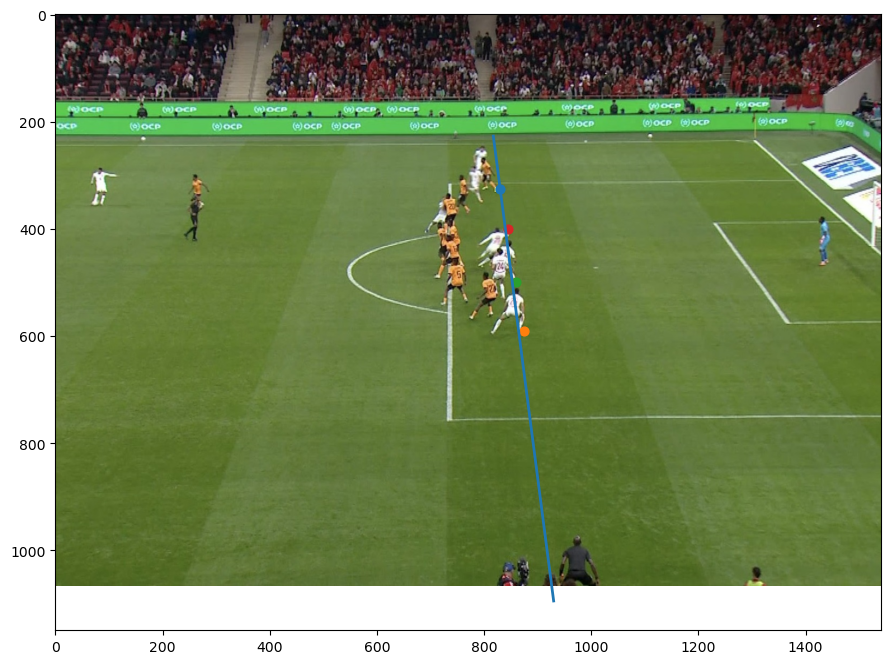

In [15]:
# Generamos la recta paralela a la linea de fondo que pasa por el defensor
rectaCancha = alc.generarRectaCancha(Ud)

# Proyectamos la recta a las coordenadas de la imagen
rectaImagen = alc.proyectarRectaImagen(H, rectaCancha)

# Mostramos la imagen
plt.figure(figsize=(12, 8))
plt.imshow(imagenFuera)

# Dibujamos la recta sobre la imagen
plt.plot(rectaImagen[:, 0], rectaImagen[:, 1], linewidth=2)

# Marcamos los pies del ultimo defensor
plt.scatter(puntoDefensorImg[0], puntoDefensorImg[1], s=40)

# Coordenadas de los rivales
punto1rivalImg = np.array([875, 590])
punto2rivalImg = np.array([860, 500])
punto3rivalImg = np.array([845,400])

puntosRivalesImg = np.array([
    punto1rivalImg,
    punto2rivalImg,
    punto3rivalImg
])

# Marcamos los pies de los jugadores rivales
for punto in puntosRivalesImg:
    plt.scatter(punto[0], punto[1], s=40)

plt.show()

Por ultimo, analizamos si los jugadores rivales estan realmente adelantados. 

Para ello, creamos la funcion `analizarPosiciones(H, puntoDefensorImg, puntosRivalesImg, atacaHaciaUPositivo=True)` que compara las posiciones de los jugadores rivales con el ultimo defensor. Dentro de la funcion proyectamos los puntos de estos jugadores a la cancha y, dependiendo de la direccion hacia la que estan atacando, determinamos si estan fuera de lugar. La funcion imprime la situacion de cada rival.

In [16]:
# Analizamos si los jugadores rivales estan adelantados
resultados = alc.analizarPosiciones(
    H,
    puntoDefensorImg,
    puntosRivalesImg,
    atacaHaciaUPositivo=True
)

for resultado in resultados:
    print(
        f"Jugador: {resultado['Jugador']}\n"
        f"U: {resultado['U']:.2f}\n"
        f"V: {resultado['V']:.2f}\n"
        f"U del Defensor: {resultado['Ud']:.2f}\n"
        f"¿Adelantado?: {resultado['Adelantado']}\n"
    )

Jugador: 1
U: 90.92
V: 23.74
U del Defensor: 90.73
¿Adelantado?: Si

Jugador: 2
U: 90.88
V: 30.99
U del Defensor: 90.73
¿Adelantado?: Si

Jugador: 3
U: 90.85
V: 41.15
U del Defensor: 90.73
¿Adelantado?: Si



### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$.

Nota: El archivo contiene únicamente 5 puntos de control, cantidad insuficiente para calibración DLT 3D en una sola vista (que requiere al menos 6 puntos no coplanares según lo visto en el Ejercicio 1). Como la diferencia de altura del cordón ($Z = 0.1$ m) es despreciable respecto a las distancias de la escena (hasta 80 metros), aproximamos los puntos como coplanares sobre la calle ($Z \approx 0$) y estimamos las 4 homografías correspondientes para obtener $K$ mediante el método de Zhang.

In [17]:
# Cargamos los 5 puntos de control y sus coordenadas en las 4 vistas
df = pd.read_csv('salguero/world_img_pts.csv', sep=';')
datos = np.asarray(df)
objPts_a = datos[:, 1:3]  # Coordenadas (X, Y) en metros

H_lista = []
for i in range(4):
    u = 4 + 2 * i
    v = 4 + 2 * i + 1
    imgPts_a = datos[:, u:v+1]
    Q2d = alc.obtenerQ2d(imgPts_a, objPts_a)
    _, _, V = alc.svd_reducida(Q2d, k=9, tol=-1)
    Hk = V[:, -1].reshape((3, 3))
    H_lista.append(Hk)

A_Zhang = alc.armarA(H_lista)
K_salguero = alc.calcularMatrizK2D(A_Zhang)

print("Matriz intrínseca K estimada para Salguero:")
print(K_salguero)

Matriz intrínseca K estimada para Salguero:
[[2.78278008e+03 1.35536578e+03 2.89090322e+02]
 [0.00000000e+00 2.13055733e+02 1.95627005e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

Matriz de rotación R:
[[ 0.97355714  0.22641062  0.03040938]
 [ 0.04495165 -0.05935242 -0.99722447]
 [-0.22397734  0.97222195 -0.0679605 ]]

Vector de traslación t:
[-21.54867297  49.81731996  33.64599434]


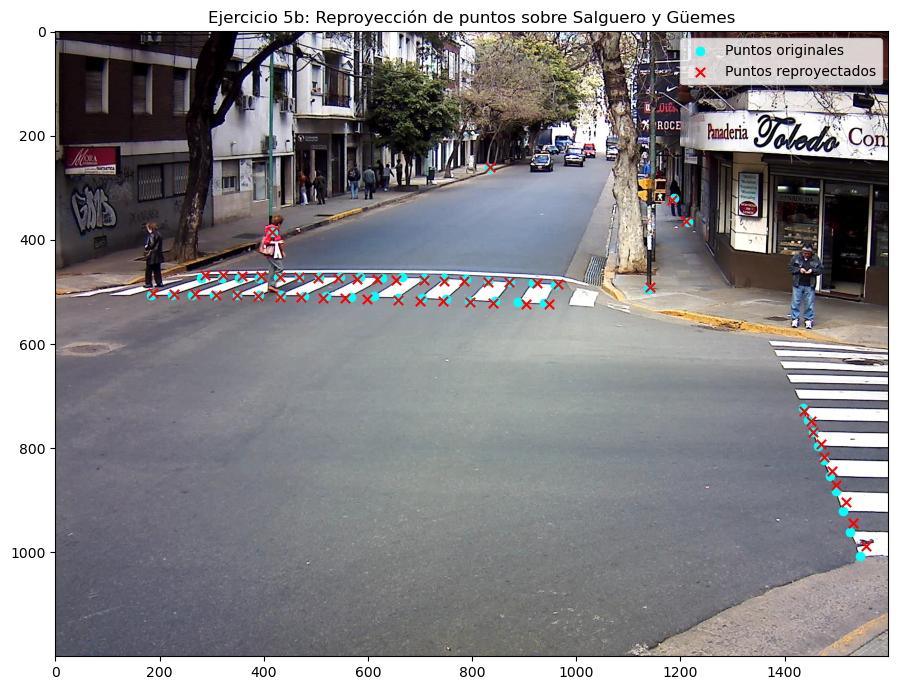

In [18]:
datos_b = np.loadtxt('salguero/gs_10_09_point_correspondences_v5.txt')
objPts_b = alc.traspuesta(datos_b[1:4, :])
imgPts_b = alc.traspuesta(datos_b[4:6, :])

# Filtramos los puntos sobre la calzada (Z = 0) para calcular la homografía del plano
mask_calle = (objPts_b[:, 2] == 0.0)
objPts_calle = objPts_b[mask_calle, 0:2]
imgPts_calle = imgPts_b[mask_calle, :]

# Normalización isotrópica de Hartley para condicionar numéricamente el cálculo
obj_norm, T_mundo = alc.normalizar2D(objPts_calle)
img_norm, T_img = alc.normalizar2D(imgPts_calle)

Q_b = alc.obtenerQ2d(img_norm, obj_norm)
_, _, V_b = alc.svd_reducida(Q_b, k=9, tol=-1)
H_b_norm = V_b[:, -1].reshape((3, 3))

# Desnormalizamos: H_b = T_img^(-1) * H_norm * T_mundo
H_b = alc.prodMat(alc.prodMat(alc.inversa(T_img), H_b_norm), T_mundo)
H_b = H_b / H_b[2, 2]

R_salguero, t_salguero = alc.obtenerPose2D(H_b, K_salguero)
print("Matriz de rotación R:")
print(R_salguero)
print("\nVector de traslación t:")
print(t_salguero)

# Reproyección de los puntos sobre la calzada
unos = np.ones((1, objPts_calle.shape[0]))
puntos_homog = np.vstack((alc.traspuesta(objPts_calle), unos))
proy_h = alc.prodMat(H_b, puntos_homog)
u_proy = proy_h[0, :] / proy_h[2, :]
v_proy = proy_h[1, :] / proy_h[2, :]

img_salg = plt.imread('salguero/img_10_18_47_351.jpg')
plt.figure(figsize=(10, 7))
plt.imshow(img_salg)
plt.scatter(imgPts_b[:, 0], imgPts_b[:, 1], color='cyan', s=35, label='Puntos originales')
plt.scatter(u_proy, v_proy, color='red', marker='x', s=45, label='Puntos reproyectados')
plt.title('Ejercicio 5b: Reproyección de puntos sobre Salguero y Güemes')
plt.legend()
plt.tight_layout()
plt.show()

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

Señora de buzo rojo:
  Distancia total recorrida: 6.88 m
  Tiempo transcurrido: 4.96 s
  Velocidad media: 1.39 m/s (4.99 km/h)

Taxi:
  Distancia total recorrida: 59.65 m
  Tiempo transcurrido: 4.96 s
  Velocidad media: 12.02 m/s (43.28 km/h)

Camioneta:
  Distancia total recorrida: 74.42 m
  Tiempo transcurrido: 4.96 s
  Velocidad media: 15.00 m/s (54.00 km/h)



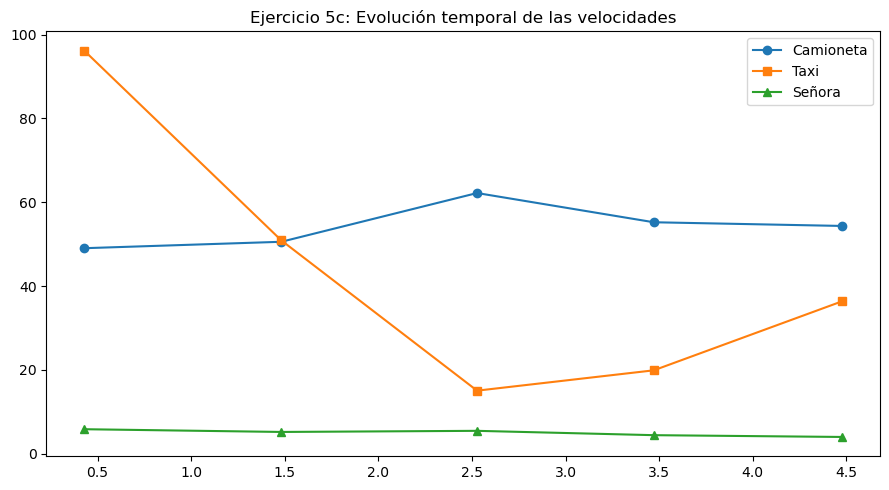

In [19]:
H_inv = alc.inversa(H_b)

def procesar_agente(archivo, nombre):
    data = np.loadtxt(archivo)
    tiempos = data[:, 0]
    pts_img = np.ones((len(data), 3))
    pts_img[:, 0:2] = data[:, 1:3]
    
    pts_mundo = []
    for i in range(len(data)):
        p = alc.calcularAx(H_inv, pts_img[i])
        pts_mundo.append([p[0] / p[2], p[1] / p[2]])
    pts_mundo = np.array(pts_mundo)
    
    # Distancia euclídea acumulada sobre el piso
    diffs = np.diff(pts_mundo, axis=0)
    distancias = np.sqrt(np.sum(diffs**2, axis=1))
    distancia_total = np.sum(distancias)
    dt_total = tiempos[-1] - tiempos[0]
    
    v_media_ms = distancia_total / dt_total
    v_media_kmh = v_media_ms * 3.6
    
    dt_pasos = np.diff(tiempos)
    v_instantanea_kmh = (distancias / dt_pasos) * 3.6
    tiempos_medios = tiempos[:-1] + dt_pasos / 2
    
    print(f"{nombre}:")
    print(f"  Distancia total recorrida: {distancia_total:.2f} m")
    print(f"  Tiempo transcurrido: {dt_total:.2f} s")
    print(f"  Velocidad media: {v_media_ms:.2f} m/s ({v_media_kmh:.2f} km/h)\n")
    
    return tiempos_medios, v_instantanea_kmh, pts_mundo

t_señora, v_señora, coords_señora = procesar_agente('señora.txt', 'Señora de buzo rojo')
t_taxi, v_taxi, coords_taxi = procesar_agente('taxi.txt', 'Taxi')
t_camioneta, v_camioneta, coords_camioneta = procesar_agente('camioneta.txt', 'Camioneta')

# Gráfico temporal de velocidades
plt.figure(figsize=(9, 5))
plt.plot(t_camioneta, v_camioneta, marker='o', label='Camioneta')
plt.plot(t_taxi, v_taxi, marker='s', label='Taxi')
plt.plot(t_señora, v_señora, marker='^', label='Señora')
plt.title('Ejercicio 5c: Evolución temporal de las velocidades')
plt.legend()
plt.tight_layout()
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$ y la matriz intrínseca $\mathbf{K}$.

Se toman los 5 puntos de control coplanares provistos en $\texttt{object\_points.csv}$ correspondientes a la mira tipo H:
- $M_0$: Centro de la H (origen del sistema del objeto, $[0, 0, 0]$ m)
- $M_1$: Extremo exterior superior izquierdo ($[-0.175, 0.3, 0]$ m)
- $M_2$: Extremo exterior superior derecho ($[0.175, 0.3, 0]$ m)
- $M_3$: Extremo exterior inferior derecho ($[0.175, -0.3, 0]$ m)
- $M_4$: Extremo exterior inferior izquierdo ($[-0.175, -0.3, 0]$ m)

Matriz de rotación R:
[[-0.18759019 -0.94236465  0.27705377]
 [-0.91090634  0.06136962 -0.40802378]
 [ 0.3675045  -0.32891129 -0.86991827]]

Vector de traslación t:
[-0.67127336  0.87460737  4.28550877]

Altura estimada a la mira (Z0): 4.29 metros
Puntos proyectados válidos (Zi > 0): 5/5
Error RMS de reproyección: 3.777 px


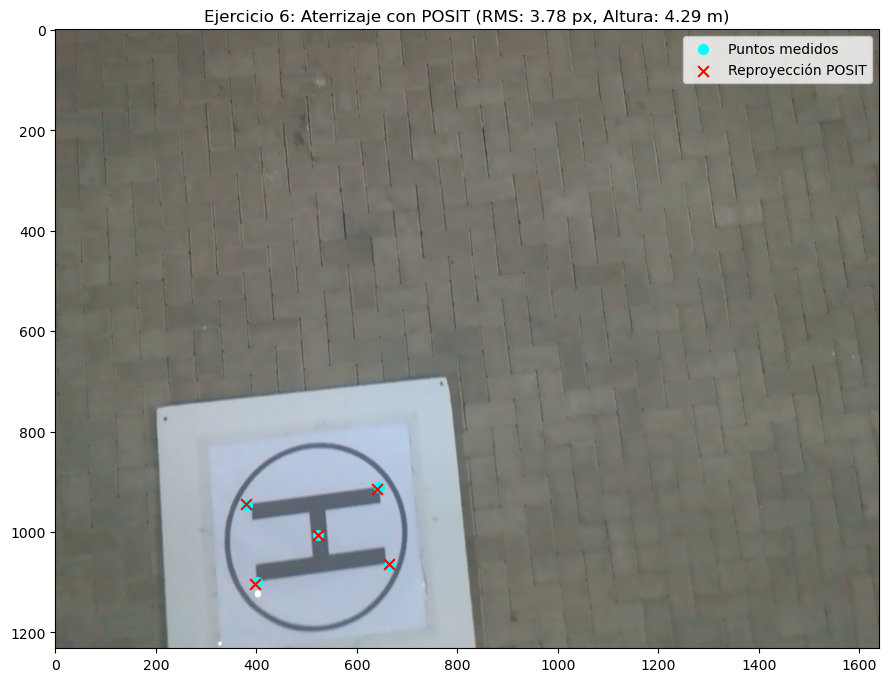

In [20]:
img_heli = plt.imread('heli/row_00248.png')

K_heli = np.array([
    [1892.9,    0.0, 819.5],
    [   0.0, 1909.5, 615.5],
    [   0.0,    0.0,   1.0]
])

# Coordenadas 3D del objeto (en metros)
obj_pts_heli = np.array([
    [ 0.000,  0.000, 0.0],  # M0: Centro de la H
    [-0.175,  0.300, 0.0],  # M1: Sup Izq
    [ 0.175,  0.300, 0.0],  # M2: Sup Der
    [ 0.175, -0.300, 0.0],  # M3: Inf Der
    [-0.175, -0.300, 0.0],  # M4: Inf Izq
])

# Coordenadas 2D medidas en la imagen (u, v en píxeles)
img_pts_heli = np.array([
    [523.0, 1005.2],  # M0: Centro de la H
    [401.3, 1099.2],  # M1
    [381.2,  945.5],  # M2
    [644.6,  911.1],  # M3
    [664.7, 1064.9],  # M4
])

# Estimamos la pose con POSIT
R_heli, t_heli = alc.aplicarPOSIT(obj_pts_heli, img_pts_heli, K_heli, MaxIt=20, atol=1e-4)

print("Matriz de rotación R:")
print(R_heli)
print("\nVector de traslación t:")
print(t_heli)
print(f"\nAltura estimada a la mira (Z0): {t_heli[2]:.2f} metros")

# Evaluamos el error RMS de reproyección
validas, rms = alc.evaluarPose(R_heli, t_heli, obj_pts_heli, img_pts_heli, K_heli)
print(f"Puntos proyectados válidos (Zi > 0): {validas}/5")
print(f"Error RMS de reproyección: {rms:.3f} px")

# Reproyección sobre la imagen del drone
proy_heli = []
for pt in obj_pts_heli:
    Pc = alc.prodMat(R_heli, pt).flatten() + t_heli
    p = alc.prodMat(K_heli, Pc).flatten()
    proy_heli.append([p[0] / p[2], p[1] / p[2]])
proy_heli = np.array(proy_heli)

plt.figure(figsize=(9, 7))
plt.imshow(img_heli)
plt.scatter(img_pts_heli[:, 0], img_pts_heli[:, 1], color='cyan', s=50, label='Puntos medidos')
plt.scatter(proy_heli[:, 0], proy_heli[:, 1], color='red', marker='x', s=60, label='Reproyección POSIT')
plt.title(f'Ejercicio 6: Aterrizaje con POSIT (RMS: {rms:.2f} px, Altura: {t_heli[2]:.2f} m)')
plt.legend()
plt.tight_layout()
plt.show()

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda).

Para ubicar al drone exactamente sobre el centro de la letra H ($M_0 = [0, 0, 0]$ m) a la altura actual $h \approx 4.29$ m y viendo la H en posición vertical:
1. El eje óptico de la cámara $Z_c$ debe apuntar perpendicularmente al suelo (dirección $-W$).
2. El eje horizontal de la imagen $X_c$ debe quedar paralelo y alineado con el eje $+U$ de la mira.
3. El eje vertical de la imagen $Y_c$ debe quedar alineado con el eje $-V$ de la mira (de modo que la parte superior de la H, en $V > 0$, quede en la parte superior de la imagen).

La rotación objetivo es:
$$R_{target} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & -1 & 0 \\ 0 & 0 & -1 \end{bmatrix}$$

y el vector de traslación objetivo es:
$$t_{target} = \begin{bmatrix} 0 \\ 0 \\ h \end{bmatrix}$$
con $h \approx 4.29$ m.

In [21]:
# Posición actual del centro óptico del drone en coordenadas del objeto: C = -R^T * t
C_actual = -alc.prodMat(alc.traspuesta(R_heli), t_heli.reshape((3, 1))).flatten()

# Pose objetivo para ver la H centrada y vertical
R_target = np.array([
    [ 1.0,  0.0,  0.0],
    [ 0.0, -1.0,  0.0],
    [ 0.0,  0.0, -1.0]
])
t_target = np.array([0.0, 0.0, t_heli[2]])

# Posición objetivo del drone en el sistema de la mira
C_target = np.array([0.0, 0.0, t_heli[2]])
delta_C = C_target - C_actual

print("Posición actual del drone en coordenadas de la mira:")
print(f"  C = ({C_actual[0]:.2f}, {C_actual[1]:.2f}, {C_actual[2]:.2f}) m")
print("\nMatriz de rotación objetivo R_target:")
print(R_target)
print("\nVector de traslación objetivo t_target:")
print(t_target)
print("\nDesplazamiento métrico necesario (Delta C): ")
print(f"  Delta C = ({delta_C[0]:.2f}, {delta_C[1]:.2f}, {delta_C[2]:.2f}) m")

Posición actual del drone en coordenadas de la mira:
  C = (-0.90, 0.72, 4.27) m

Matriz de rotación objetivo R_target:
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]

Vector de traslación objetivo t_target:
[0.         0.         4.28550877]

Desplazamiento métrico necesario (Delta C): 
  Delta C = (0.90, -0.72, 0.01) m


---